# 02 - Data Cleaning, Gap Handling & Exploratory Analysis
Steps: merge pollution + weather -> full daily calendar -> remove impossible values -> fill *short* gaps only -> save -> explore.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

plt.rcParams["figure.figsize"] = (11, 4)

In [11]:
poll = (pd.read_csv(RAW_DIR / f"{SLUG}_pollution.csv", parse_dates=["Date"])
        .drop_duplicates("Date").set_index("Date").sort_index())
poll = poll[["AQI"] + POLLUTANTS]

wx = pd.read_csv(RAW_DIR / f"{SLUG}_weather.csv", parse_dates=["Date"]).set_index("Date")

# Full daily calendar so that gaps show up as NaN instead of silently disappearing.
# (This matters: lags/rolling windows are only correct on a regular daily index.)
full_index = pd.date_range(poll.index.min(), poll.index.max(), freq="D")
df = poll.reindex(full_index).join(wx)
df.index.name = "Date"
print("Rows:", len(df))

Rows: 901


### Missing values before cleaning

In [12]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

AQI         95.4
PM2.5       95.4
PM10        95.4
NO2         95.4
SO2         95.4
O3          95.1
CO          95.0
temp         0.0
humidity     0.0
wind         0.0
precip       0.0
pressure     0.0
dtype: float64


### Cleaning rules
1. Negative pollutant/AQI values are impossible -> set to NaN.
2. Extreme spikes above the 99.9th percentile are capped (sensor glitches).
3. Gaps of up to **5 days** are linearly interpolated. Longer gaps stay NaN - we do not invent weeks of data.

In [13]:
num_cols = ["AQI"] + POLLUTANTS
for c in num_cols:
    df.loc[df[c] < 0, c] = np.nan
    df[c] = df[c].clip(upper=df[c].quantile(0.999))

fill_cols = num_cols + WEATHER
df[fill_cols] = df[fill_cols].interpolate(limit=5, limit_area="inside")

print("Missing after cleaning (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
df.to_csv(CLEAN_PATH)
print("Saved ->", CLEAN_PATH)

Missing after cleaning (%):
AQI         94.5
PM2.5       94.5
PM10        94.5
NO2         94.5
SO2         94.5
CO          94.5
O3          94.5
temp         0.0
humidity     0.0
wind         0.0
precip       0.0
pressure     0.0
dtype: float64
Saved -> C:\Users\RAJESHWARI SAHU\AQI-Forecasting-System\data\processed\delhi_clean.csv


## Exploratory Analysis
### 1. AQI over time

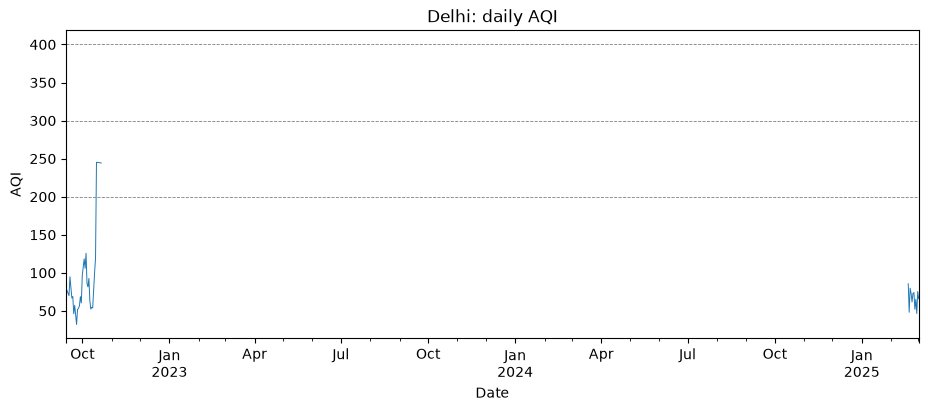

In [14]:
fig, ax = plt.subplots()
df["AQI"].plot(ax=ax, lw=0.7)
for b in AQI_BINS[2:]:
    ax.axhline(b, color="grey", ls="--", lw=0.6)
ax.set_title(f"{CITY}: daily AQI"); ax.set_ylabel("AQI")
fig.savefig(FIG_DIR / "eda_aqi_timeseries.png", dpi=150, bbox_inches="tight"); plt.show()

### 2. Seasonality - month and weekday

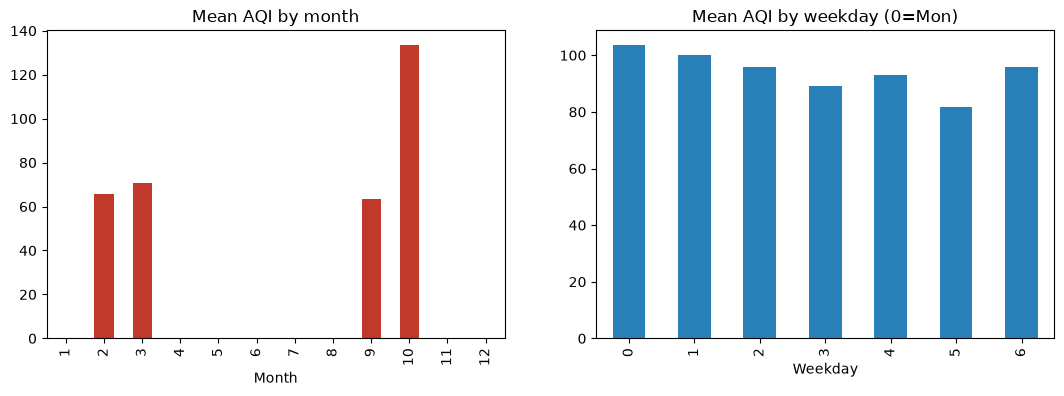

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(df.index.month)["AQI"].mean().plot.bar(ax=axes[0], color="#c0392b")
axes[0].set_title("Mean AQI by month"); axes[0].set_xlabel("Month")
df.groupby(df.index.dayofweek)["AQI"].mean().plot.bar(ax=axes[1], color="#2980b9")
axes[1].set_title("Mean AQI by weekday (0=Mon)"); axes[1].set_xlabel("Weekday")
fig.savefig(FIG_DIR / "eda_seasonality.png", dpi=150, bbox_inches="tight"); plt.show()

### 3. How does weather relate to AQI?

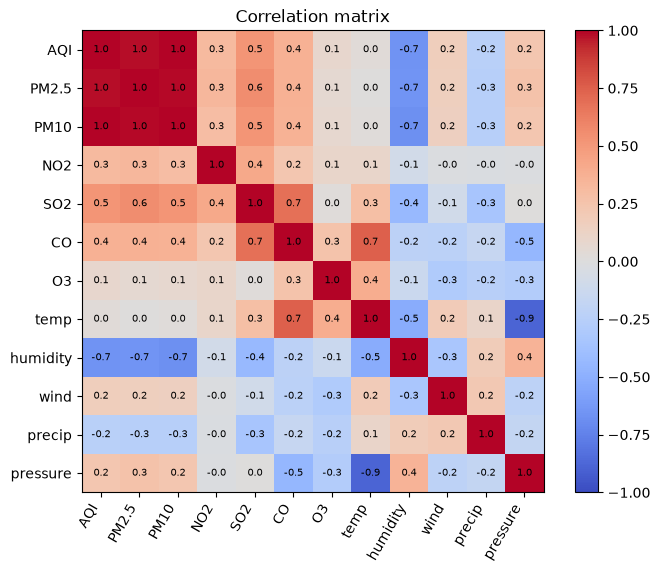

In [16]:
cols = ["AQI"] + POLLUTANTS + WEATHER
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Correlation matrix")
fig.savefig(FIG_DIR / "eda_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

### 4. Pollution events (Diwali / stubble season)

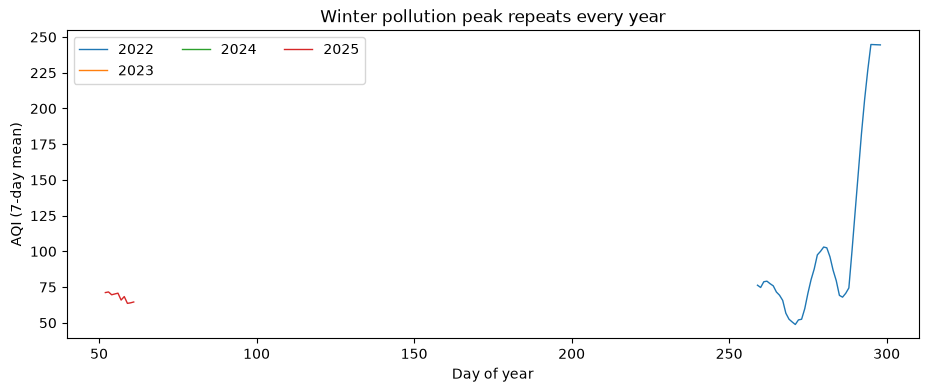

In [17]:
yr = df.copy()
yr["year"] = yr.index.year
yr["doy"] = yr.index.dayofyear
fig, ax = plt.subplots()
for y, g in yr.groupby("year"):
    ax.plot(g["doy"], g["AQI"].rolling(7, min_periods=3).mean(), label=str(y), lw=1)
ax.set_xlabel("Day of year"); ax.set_ylabel("AQI (7-day mean)")
ax.set_title("Winter pollution peak repeats every year"); ax.legend(ncol=3)
fig.savefig(FIG_DIR / "eda_yearly_overlay.png", dpi=150, bbox_inches="tight"); plt.show()

### 5. Day-to-day persistence
Tomorrow's AQI is strongly related to today's - this is why a **persistence baseline** is hard to beat and is the benchmark all models must beat.

In [18]:
print("Correlation of AQI(t) with AQI(t+h):")
for h in [1, 2, 3, 7]:
    print(f"  h={h}: {df['AQI'].corr(df['AQI'].shift(-h)):.3f}")

Correlation of AQI(t) with AQI(t+h):
  h=1: 0.914
  h=2: 0.835
  h=3: 0.712
  h=7: -0.256
